# Bitcoin: predicting the *size* of each hourly move (Filip)

**Task.** Same setup as the rest of the project: from the last 7 days of hourly data, predict 24 values for the next day. The difference is the target. Instead of the signed change `Close[h] / Close[h-1] − 1`, we predict **how big the change will be, regardless of direction**:

$$\text{size}_h = \left|\frac{\text{Close}_h}{\text{Close}_{h-1}} - 1\right| \quad (\text{in } \%)$$

**Why.** The team showed (Alberto, Adrián, `svr-voting-ensemble.ipynb`) that the *direction* of hourly changes cannot be predicted better than "no change". Two well-known properties of financial prices suggest the *size* can:

- **Volatility clustering:** calm hours tend to follow calm hours, wild hours follow wild hours.
- **Daily rhythm:** some hours of the day (for example when US markets open) are busier than others.

Alberto already found that the size of the *whole next day* is predictable (R² = 0.45). This notebook asks the same question **hour by hour**, using the same models: Ridge, Random Forest, Gradient Boosting, Linear SVR and their voting ensemble.

## 1. Shared setup from Alberto's notebook

Data, the 42 features, the training period, the walk-forward folds and the helpers `cv_tune` and `best_params` come from `bitcoin-models-new-data.ipynb` through `shared_cells.py`, so nothing is copied.

In [1]:
from shared_cells import run_shared_cells

run_shared_cells(globals())

from sklearn.svm import LinearSVR

42 features | train 9950 windows (2017-01-01 -> 2023-10-24) | test 25815 windows (2023-10-25 -> 2026-10-05) | 4 CV folds


## 2. Target and extra features

**Target:** `|Ytr|` and `|Yte|`, the absolute hourly changes in %.

**Extra features.** Alberto's features were designed for the *signed* change. For the size, two groups are added (48 features):

| Group | Features | Idea |
|---|---|---|
| Recent move sizes | `|return|` of the last 24 hours | volatility clustering; Ridge cannot compute `|x|` from the signed lags by itself |
| Same hour, last 7 days | for each of the 24 target hours: the average move size at that hour of the day over the past week | daily rhythm |

In [2]:
def size_features(X):
    a = np.abs(window_returns(X))                       # (n, 168) move sizes of the input week, in %
    recent = a[:, ::-1][:, :24]                         # last 24 hours, most recent first
    # target hour h (1..24) is at position 167 + h; the same hour on earlier days is at h - 1 + 24 * k
    same_hour = np.stack([a[:, h - 1::24].mean(1) for h in range(1, TARGET_HOURS + 1)], axis=1)
    names = [f"abs_lag{k}" for k in range(1, 25)] + [f"same_hour_mean_h{h}" for h in range(1, 25)]
    return np.hstack([recent, same_hour]), names

idx_tr = np.searchsorted(dates_train, Dtr)              # the training windows Alberto's setup selected
assert (dates_train[idx_tr] == Dtr).all()
S_tr, size_names = size_features(X_train[idx_tr])
S_te, _ = size_features(X_test[PURGE:])

FStr, FSte = np.hstack([Ftr, S_tr]), np.hstack([Fte, S_te])
all_names = feature_names + size_names
Atr, Ate = np.abs(Ytr), np.abs(Yte)

print(f"Features: {FStr.shape[1]} ({len(feature_names)} from Alberto + {len(size_names)} new)")
print(f"Average move size: train {Atr.mean():.3f} %, test {Ate.mean():.3f} %")

Features: 90 (42 from Alberto + 48 new)
Average move size: train 0.499 %, test 0.325 %


## 3. Metrics and baselines

Predicting "0" is meaningless for a size, so the baselines are simple volatility rules that need no learning:

| Baseline | Prediction for hour *h* |
|---|---|
| **Training average per hour** | average move size of that hour in the training period (a constant) |
| **Last 24 h average** | average move size of the last 24 hours |
| **Last week average** | average move size of the whole input week |
| **Same hour, last 7 days** | average size at the same hour of the day during the input week |

Metrics:

| Metric | Meaning |
|---|---|
| **MAE** | average error per hour, in % |
| **Skill vs. last week** | `1 − MAE_model / MAE_last-week-average`. Above 0 means better than the best simple rule (see the baselines). |
| **R²** | share of the variation in move sizes that is explained |
| **Corr** | correlation between predicted and real move sizes |

The best model is still chosen on walk-forward CV only, and the test period is used once per model.

In [3]:
size_results, size_preds = [], {}
a_in = np.abs(window_returns(X_test[PURGE:]))                    # move sizes of the input weeks, in %
last_week = np.repeat(a_in.mean(1, keepdims=True), 24, axis=1)
mae_last_week = mean_absolute_error(Ate, last_week)

def size_report(name, pred):
    mae = mean_absolute_error(Ate, pred)
    row = {"Model": name, "MAE": mae, "Skill_vs_last_week": 1 - mae / mae_last_week,
           "R2": r2_score(Ate.ravel(), pred.ravel()), "Corr": safe_corr(pred, Ate)}
    size_results.append(row)
    size_preds[name] = pred
    print(f"{name:<45} MAE={mae:.4f}  skill_vs_last_week={row['Skill_vs_last_week']:+.4f}  "
          f"R2={row['R2']:+.4f}  corr={row['Corr']:.3f}")

size_report("Baseline: last week average", last_week)
size_report("Baseline: training average per hour", np.tile(Atr.mean(0), (len(Ate), 1)))
size_report("Baseline: last 24 h average", np.repeat(a_in[:, -24:].mean(1, keepdims=True), 24, axis=1))
size_report("Baseline: same hour, last 7 days", S_te[:, 24:])

Baseline: last week average                   MAE=0.2420  skill_vs_last_week=+0.0000  R2=+0.0337  corr=0.200
Baseline: training average per hour           MAE=0.3336  skill_vs_last_week=-0.3789  R2=-0.2093  corr=0.000
Baseline: last 24 h average                   MAE=0.2454  skill_vs_last_week=-0.0142  R2=+0.0090  corr=0.223
Baseline: same hour, last 7 days              MAE=0.2499  skill_vs_last_week=-0.0328  R2=-0.0208  corr=0.221


## 4. Models and hyperparameters

The same walk-forward CV as in the rest of the project (`cv_tune`). In the CV tables, **look at `val_MAE`** (lower is better). The columns `val_skill`, `val_IC` and `val_DayDirAcc` are computed by the shared helper for the signed target. `val_skill` is measured against predicting 0, so here it only ranks the settings in the same order as `val_MAE`.

All models use **absolute error (MAE) loss where possible**. Move sizes have a long right tail (a few huge hours), and MAE loss makes the model predict the median, which is what the MAE metric rewards.

### 4.1 Ridge

In [4]:
make_ridge_s = lambda alpha: make_pipeline(StandardScaler(), Ridge(alpha=alpha))
ridge_s_cv = cv_tune(make_ridge_s, {"alpha": [0.1, 1, 10, 100, 1_000, 10_000]}, X=FStr, Y=Atr)
p_ridge_s = best_params(ridge_s_cv, ["alpha"])

,alpha,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,1000.0,0.2872,0.2199,0.0775,0.3363,0.3297,1.0,0.4
1,100.0,0.2889,0.2118,0.0854,0.3402,0.3213,1.0,0.5
2,10.0,0.2897,0.2051,0.0950,0.3432,0.3222,1.0,0.4
3,0.1,0.2901,0.2039,0.0974,0.3437,0.3252,1.0,0.3
4,1.0,0.2901,0.2038,0.0976,0.3437,0.3246,1.0,0.4
5,10000.0,0.2774,0.2009,0.1044,0.3436,0.3367,1.0,0.4


### 4.2 Linear SVR

The ε-insensitive loss is close to MAE, which suits this target.

In [5]:
make_lsvr_s = lambda C, epsilon: make_pipeline(StandardScaler(), MultiOutputRegressor(
    LinearSVR(C=C, epsilon=epsilon, max_iter=10_000, dual="auto", random_state=RANDOM_STATE)))
lsvr_s_cv = cv_tune(make_lsvr_s, {"C": [0.0001, 0.001, 0.01, 0.1], "epsilon": [0.0, 0.05]}, X=FStr, Y=Atr)
p_lsvr_s = best_params(lsvr_s_cv, ["C", "epsilon"])

,C,epsilon,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,0.0010,0.05,0.3344,0.3162,0.0197,0.2967,0.3291,1.0,1.2
1,0.0010,0.00,0.3350,0.3155,0.0198,0.2971,0.3284,1.0,1.2
2,0.0100,0.05,0.3434,0.3103,0.0304,0.2991,0.3261,1.0,5.3
3,0.0100,0.00,0.3443,0.3102,0.0300,0.2992,0.3258,1.0,4.8
4,0.1000,0.05,0.3445,0.3070,0.0359,0.3005,0.3277,1.0,44.1
5,0.1000,0.00,0.3454,0.3069,0.0356,0.3006,0.3273,1.0,35.1
6,0.0001,0.05,0.2442,0.2459,0.0582,0.3282,0.3344,1.0,0.8
7,0.0001,0.00,0.2442,0.2448,0.0576,0.3287,0.3333,1.0,0.9


### 4.3 Random Forest

One forest predicts all 24 hours together.

In [6]:
make_rf_s = lambda **p: RandomForestRegressor(n_estimators=100, max_features=0.3, n_jobs=-1,
                                              random_state=RANDOM_STATE, **p)
rf_s_cv = cv_tune(make_rf_s, {"max_depth": [6, 10, 16], "min_samples_leaf": [10, 50]}, X=FStr, Y=Atr)
p_rf_s = best_params(rf_s_cv, ["max_depth", "min_samples_leaf"])

,max_depth,min_samples_leaf,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,16,50,0.2927,0.2236,0.0801,0.3345,0.3381,1.0,2.6
1,10,50,0.2922,0.2234,0.0803,0.3345,0.3380,1.0,2.6
2,6,50,0.2873,0.2204,0.0823,0.3356,0.3361,1.0,2.4
3,16,10,0.3381,0.2183,0.0858,0.3364,0.3397,1.0,4.1
4,10,10,0.3187,0.2177,0.0871,0.3366,0.3387,1.0,3.4
5,6,10,0.2967,0.2107,0.0958,0.3393,0.3369,1.0,2.6


### 4.4 Gradient Boosting

One model per predicted hour, with MAE loss.

In [7]:
make_gb_s = lambda **p: MultiOutputRegressor(HistGradientBoostingRegressor(
    loss="absolute_error", max_iter=300, min_samples_leaf=50, early_stopping=True,
    random_state=RANDOM_STATE, **p), n_jobs=-1)
gb_s_cv = cv_tune(make_gb_s, {"learning_rate": [0.05, 0.1], "max_depth": [3, 5]}, X=FStr, Y=Atr)
p_gb_s = best_params(gb_s_cv, ["learning_rate", "max_depth"])

,learning_rate,max_depth,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,0.10,3,0.3675,0.3119,0.0277,0.2984,0.3297,1.0,5.4
1,0.05,3,0.3626,0.3114,0.0296,0.2986,0.3309,1.0,10.2
2,0.05,5,0.3957,0.3084,0.0323,0.2998,0.3289,1.0,10.7
3,0.10,5,0.4031,0.3079,0.0310,0.3000,0.3264,1.0,7.4


## 5. Voting ensemble

The average of the four tuned models. It is checked on the same CV folds first, then evaluated once on the test period with the other models.

In [8]:
SIZE_MEMBERS = {
    "Ridge": lambda: make_ridge_s(**p_ridge_s),
    "Linear SVR": lambda: make_lsvr_s(**p_lsvr_s),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=300, max_features=0.3, n_jobs=-1,
                                                   random_state=RANDOM_STATE, **p_rf_s),
    "Gradient Boosting": lambda: make_gb_s(**p_gb_s),
}
for name, p in [("Ridge", p_ridge_s), ("Linear SVR", p_lsvr_s), ("Random Forest", p_rf_s), ("Gradient Boosting", p_gb_s)]:
    print(f"{name:<18} best: {p}")

cv_size_preds = {name: [make().fit(FStr[tr], Atr[tr]).predict(FStr[vi]) for tr, vi in folds]
                 for name, make in SIZE_MEMBERS.items()}

def cv_mae(names):
    return np.mean([mean_absolute_error(Atr[vi], np.mean([cv_size_preds[n][k] for n in names], axis=0))
                    for k, (_, vi) in enumerate(folds)])

size_combos = {n: [n] for n in SIZE_MEMBERS}
size_combos["Ensemble: all 4"] = list(SIZE_MEMBERS)
size_combos["Ensemble: RF + GB"] = ["Random Forest", "Gradient Boosting"]
size_combos["Ensemble: Ridge + SVR + GB"] = ["Ridge", "Linear SVR", "Gradient Boosting"]
display(pd.Series({n: cv_mae(m) for n, m in size_combos.items()}, name="val_MAE").sort_values().round(4).to_frame())

Ridge              best: {'alpha': 1000}
Linear SVR         best: {'C': 0.001, 'epsilon': 0.05}
Random Forest      best: {'max_depth': 16, 'min_samples_leaf': 50}
Gradient Boosting  best: {'learning_rate': 0.1, 'max_depth': 3}


,val_MAE
Linear SVR,0.2967
Gradient Boosting,0.2984
Ensemble: Ridge + SVR + GB,0.3002
Ensemble: all 4,0.3052
Ensemble: RF + GB,0.3093
Random Forest,0.3341
Ridge,0.3363


## 6. Test period (Oct 2023 → Oct 2026)

In [9]:
fitted_size, member_size_test = {}, {}
for name, make in SIZE_MEMBERS.items():
    fitted_size[name] = make().fit(FStr, Atr)
    member_size_test[name] = fitted_size[name].predict(FSte)
    size_report(name, member_size_test[name])
for combo in ["Ensemble: all 4", "Ensemble: RF + GB", "Ensemble: Ridge + SVR + GB"]:
    size_report(combo, np.mean([member_size_test[n] for n in size_combos[combo]], axis=0))

size_summary = pd.DataFrame(size_results).drop_duplicates("Model", keep="last").set_index("Model").sort_values("MAE")
display(size_summary.round(4))

Ridge                                         MAE=0.2420  skill_vs_last_week=-0.0001  R2=+0.0705  corr=0.284


Linear SVR                                    MAE=0.2184  skill_vs_last_week=+0.0972  R2=+0.0104  corr=0.289


Random Forest                                 MAE=0.2365  skill_vs_last_week=+0.0226  R2=+0.0759  corr=0.277


Gradient Boosting                             MAE=0.2182  skill_vs_last_week=+0.0983  R2=+0.0059  corr=0.287
Ensemble: all 4                               MAE=0.2222  skill_vs_last_week=+0.0817  R2=+0.0740  corr=0.297
Ensemble: RF + GB                             MAE=0.2221  skill_vs_last_week=+0.0819  R2=+0.0653  corr=0.287
Ensemble: Ridge + SVR + GB                    MAE=0.2200  skill_vs_last_week=+0.0906  R2=+0.0613  corr=0.296


,MAE,Skill_vs_last_week,R2,Corr
Model,,,,
Gradient Boosting,0.2182,0.0983,0.0059,0.2868
Linear SVR,0.2184,0.0972,0.0104,0.2888
Ensemble: Ridge + SVR + GB,0.2200,0.0906,0.0613,0.2963
Ensemble: RF + GB,0.2221,0.0819,0.0653,0.2871
Ensemble: all 4,0.2222,0.0817,0.0740,0.2971
Random Forest,0.2365,0.0226,0.0759,0.2769
Baseline: last week average,0.2420,0.0000,0.0337,0.1998
Ridge,0.2420,-0.0001,0.0705,0.2843
Baseline: last 24 h average,0.2454,-0.0142,0.0090,0.2232


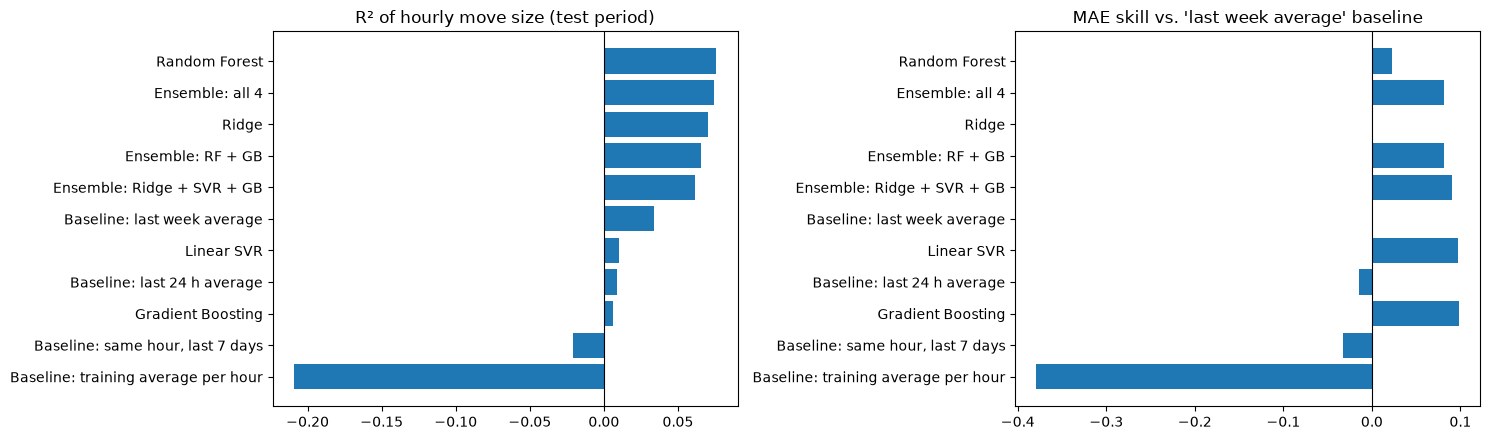

In [10]:
s = size_summary.sort_values("R2")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].barh(s.index, s["R2"]); ax[0].axvline(0, color="k", lw=0.8)
ax[0].set_title("R² of hourly move size (test period)")
ax[1].barh(s.index, s["Skill_vs_last_week"]); ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_title("MAE skill vs. 'last week average' baseline")
plt.tight_layout(); plt.show()

**Skill per forecast hour.** Is the first hour easier than hour 24?

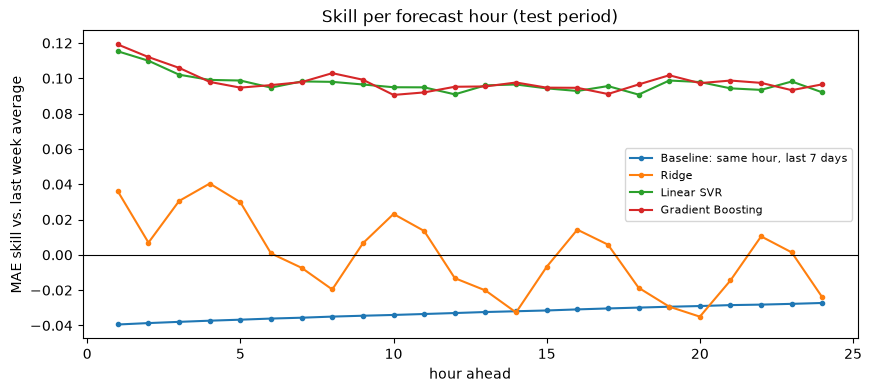

In [11]:
best_model = size_summary.drop([i for i in size_summary.index if i.startswith("Baseline")]).index[0]
ref_h = np.abs(Ate - last_week).mean(0)
plt.figure(figsize=(10, 4))
for name in dict.fromkeys(["Baseline: same hour, last 7 days", "Ridge", "Linear SVR", "Gradient Boosting", best_model]):
    plt.plot(range(1, 25), 1 - np.abs(Ate - size_preds[name]).mean(0) / ref_h, marker=".", label=name)
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("hour ahead"); plt.ylabel("MAE skill vs. last week average")
plt.title("Skill per forecast hour (test period)"); plt.legend(fontsize=8); plt.show()

**Does the model catch the daily rhythm?** Average real vs. predicted move size by hour of the day (UTC).

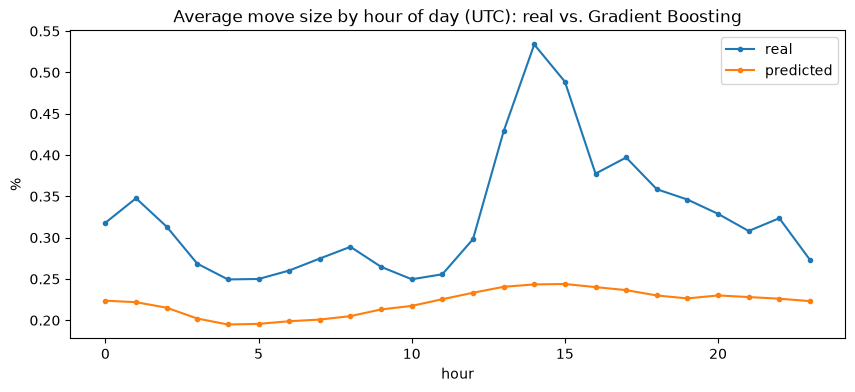

In [12]:
def hour_of_day(dates):
    # hour of day (UTC) of each of the 24 predicted hours of every window
    first = (pd.DatetimeIndex(dates) - pd.Timedelta(hours=TARGET_HOURS - 1)).hour.values
    return (first[:, None] + np.arange(TARGET_HOURS)) % 24

profile = pd.DataFrame({"hour": hour_of_day(Dte).ravel(), "real": Ate.ravel(),
                        "predicted": size_preds[best_model].ravel()}).groupby("hour").mean()
profile.plot(marker=".", figsize=(10, 4), title=f"Average move size by hour of day (UTC): real vs. {best_model}")
plt.ylabel("%"); plt.show()

**Why is the predicted rhythm so flat?** Two reasons:

1. With MAE loss the model predicts the **median** move size, which is lower and flatter than the mean (sizes have a long right tail).
2. The daily rhythm **changed**. The plot below compares the median move size per hour of day (relative to the overall median) in the training and test periods.

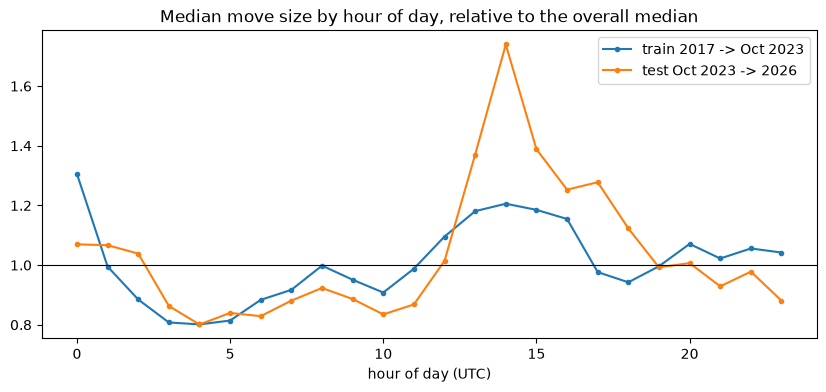

,train 2017 -> Oct 2023,test Oct 2023 -> 2026
4,0.80,0.80
14,1.21,1.74


In [13]:
def hour_profile(A, dates):
    return pd.Series(A.ravel()).groupby(hour_of_day(dates).ravel()).median() / np.median(A)

rhythm = pd.DataFrame({"train 2017 -> Oct 2023": hour_profile(Atr, Dtr),
                       "test Oct 2023 -> 2026": hour_profile(Ate, Dte)})
rhythm.plot(marker=".", figsize=(10, 4), title="Median move size by hour of day, relative to the overall median")
plt.axhline(1, color="k", lw=0.8); plt.xlabel("hour of day (UTC)"); plt.show()
display(rhythm.loc[[4, 14]].round(2))

**Example: the last 10 test days**, real move sizes vs. the forecast made at the start of each day.

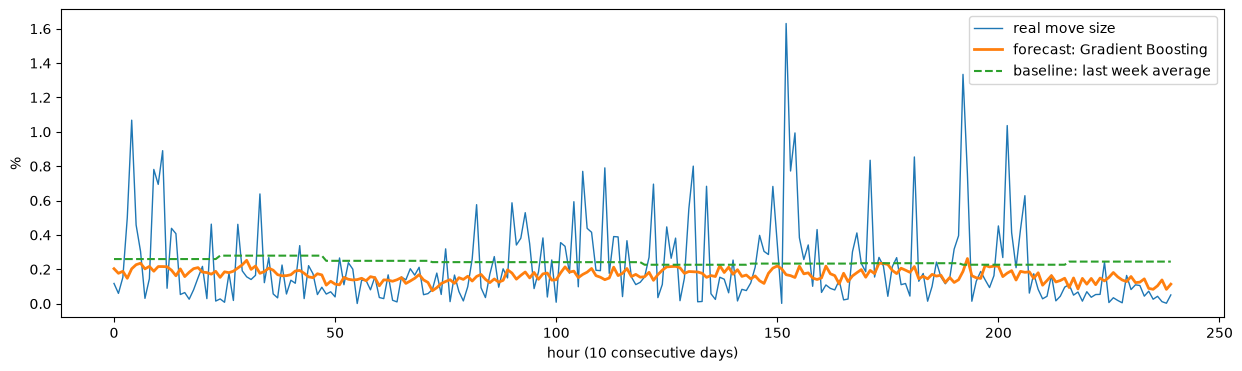

In [14]:
days = np.arange(len(Ate) - 10 * 24, len(Ate), 24)
plt.figure(figsize=(15, 4))
plt.plot(Ate[days].ravel(), label="real move size", lw=1)
plt.plot(size_preds[best_model][days].ravel(), label=f"forecast: {best_model}", lw=2)
plt.plot(last_week[days].ravel(), "--", label="baseline: last week average")
plt.xlabel("hour (10 consecutive days)"); plt.ylabel("%"); plt.legend(); plt.show()

**Which features matter?** Permutation importance of the best tree model on the test period (increase in MAE when the feature is shuffled).

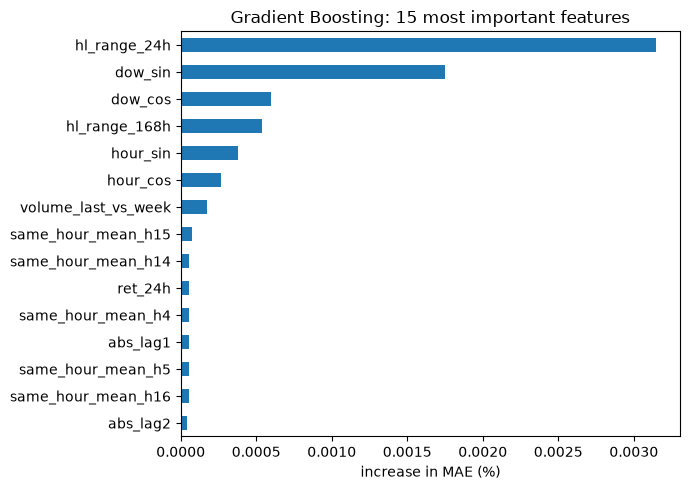

In [15]:
from sklearn.inspection import permutation_importance

tree_name = min(["Random Forest", "Gradient Boosting"], key=lambda n: size_summary.loc[n, "MAE"])
sample = np.random.default_rng(RANDOM_STATE).choice(len(FSte), 3000, replace=False)
imp = permutation_importance(fitted_size[tree_name], FSte[sample], Ate[sample], scoring="neg_mean_absolute_error",
                             n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(imp.importances_mean, index=all_names).sort_values().tail(15).plot.barh(
    figsize=(7, 5), title=f"{tree_name}: 15 most important features")
plt.xlabel("increase in MAE (%)"); plt.tight_layout(); plt.show()

## 7. Conclusions

Numbers from the run on 6 October 2026 (test period 25 Oct 2023 → 5 Oct 2026).

**1. The size of each hourly move *is* predictable, unlike its direction.**
The best models cut the error of the best simple rule ("last week's average move size", MAE 0.242 %) by about **10 %**:

| Model | MAE (%) | Skill vs. last week | R² | Corr |
|---|---|---|---|---|
| Gradient Boosting (MAE loss) | **0.218** | **+0.098** | 0.006 | 0.287 |
| Linear SVR | 0.218 | +0.097 | 0.010 | 0.289 |
| Ensemble: Ridge + SVR + GB | 0.220 | +0.091 | 0.061 | 0.296 |
| Ensemble: all 4 | 0.222 | +0.082 | 0.074 | **0.297** |
| Baseline: last week average | 0.242 | 0 | 0.034 | 0.200 |

For comparison, on the signed change the best model of the whole project (`svr-voting-ensemble.ipynb`) beat "no change" by only 0.000013.

**2. Which model is "best" depends on the metric.**
- **MAE-loss models** (Gradient Boosting, Linear SVR) have the lowest MAE but almost no R². They predict the *median* move size (≈ 0.21 %), which is what MAE rewards, but it is well below the *mean* (0.33 %) because a few hours are huge.
- **Squared-loss models** (Ridge, Random Forest) have the best R² (≈ 0.07–0.08) but their MAE is barely better than the baseline.
- **The ensemble** (Ridge + SVR + GB) is good on both: 91 % of the best MAE improvement and an R² of 0.06, with the highest correlation. It is the best all-round choice.

**3. A single hour stays noisy.** R² ≈ 0.07 looks small next to Alberto's R² = 0.45 for the *whole next day's* volatility. That is expected: the model can predict how *wild* an hour is likely to be, but the actual move in one hour is still mostly luck. Summing 24 hours averages that luck out.

**4. The signal lasts all day.** The skill is highest for hour +1 (≈ 0.12) and stays around 0.09–0.10 up to hour 24. For the direction, any trace of signal disappeared after the first hour.

**5. What the models use.** The most important features are the **high–low range of the last 24 hours** (volatility clustering), then **day of week** and **hour of day** (daily and weekly rhythm), then the weekly range and volume.

**6. The daily rhythm changed, and the models underestimate it.** In the training period (2017–2023) the busiest hour (14:00 UTC, US market open) had 1.2× the typical move size. In the test period it is **1.7×**, probably related to the US spot Bitcoin ETFs that started trading in January 2024. Because the models learned the weaker old rhythm, their forecast for US trading hours is too low. Possible next steps: train only on recent years, weight recent data more, or retrain regularly.

**7. Hyperparameters show both under- and overfitting.** Linear SVR with too small `C` (0.0001) underfits (val MAE 0.328 vs. 0.297 at `C = 0.001`). Random Forest with small leaves (`min_samples_leaf = 10`) overfits (higher train skill, lower validation skill).

**In one sentence:** from the past week, the models cannot tell whether Bitcoin will go up or down in a given hour, but they can predict **how much** it is likely to move: about 10 % better than the best simple rule, with the clearest signal coming from recent volatility and the time of day.
